Loading images...

[TASK 1] Verifying 2D Separability & Speedups
  Sigma=1.0: Speedup = 3.02x, Max Diff = 9.16e-05
  Sigma=2.0: Speedup = 6.37x, Max Diff = 2.29e-04
  Sigma=4.0: Speedup = 6.39x, Max Diff = 2.14e-04

[TASK 2] Detecting corners...


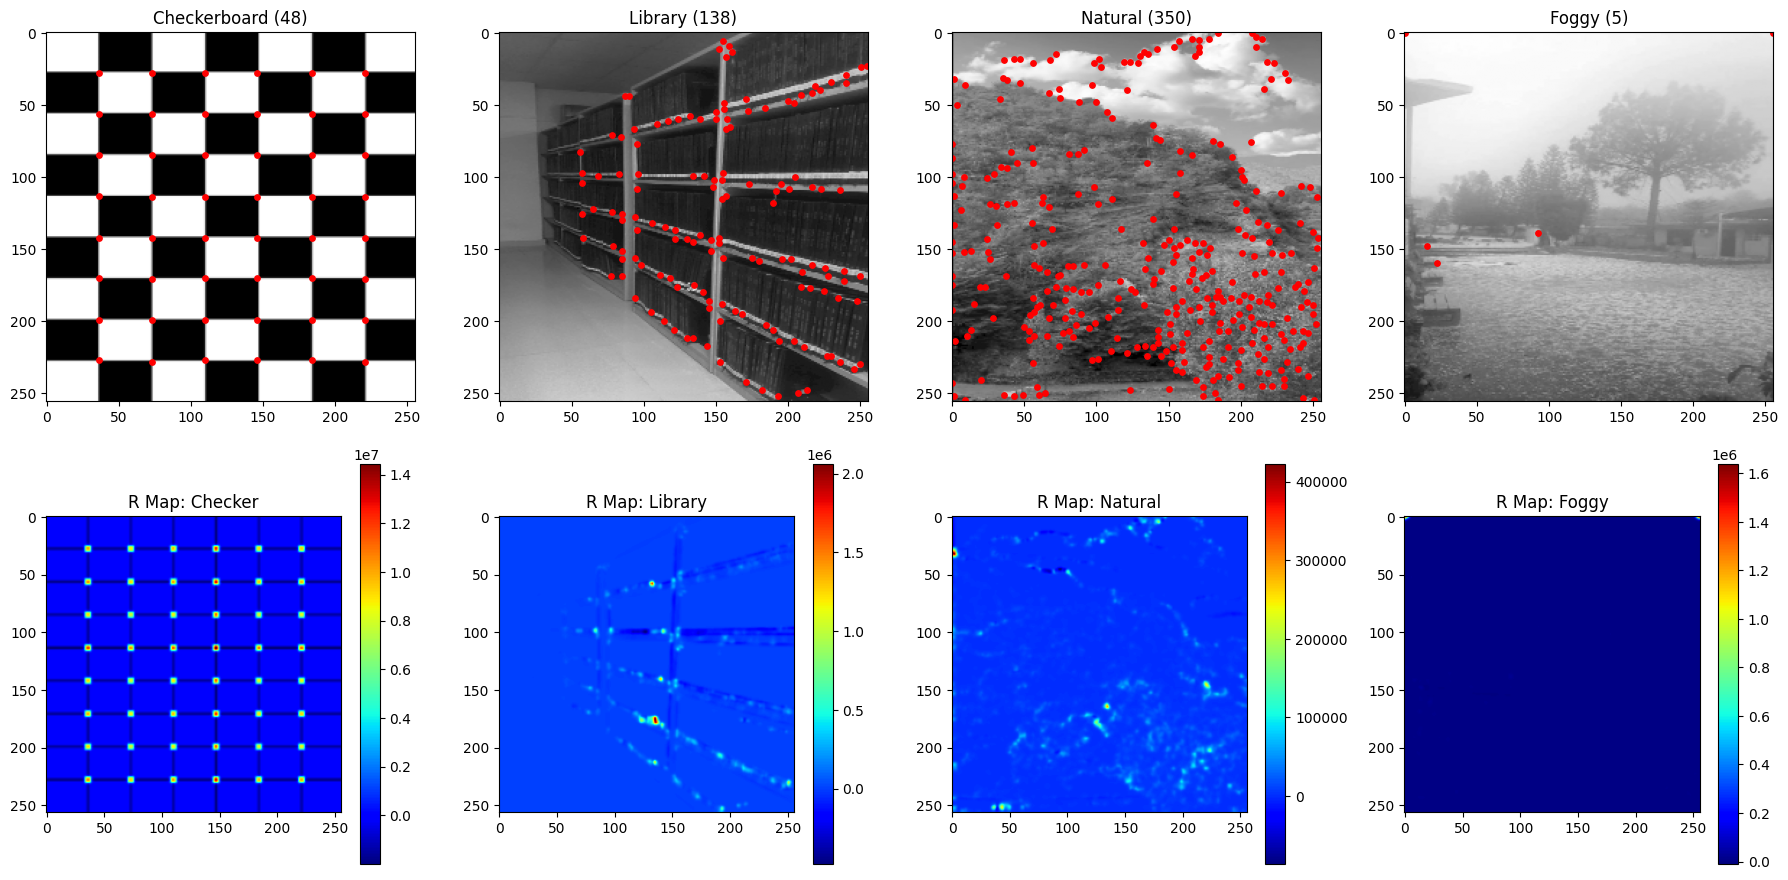


[TASK 3] Eigenvalue Analysis
  Max error det(M) - L1*L2: 1.56e+00
  Max error trace(M) - L1+L2: 4.88e-04


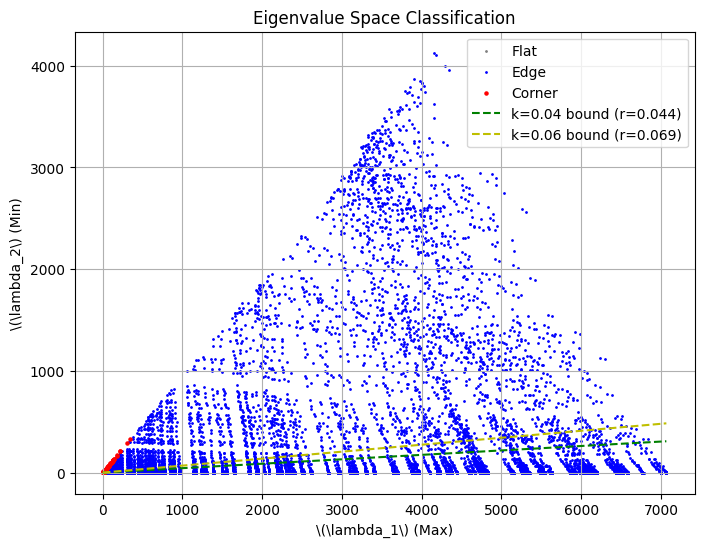


[TASK 4] Invariance Sweeps (this might take 10-20 seconds)...


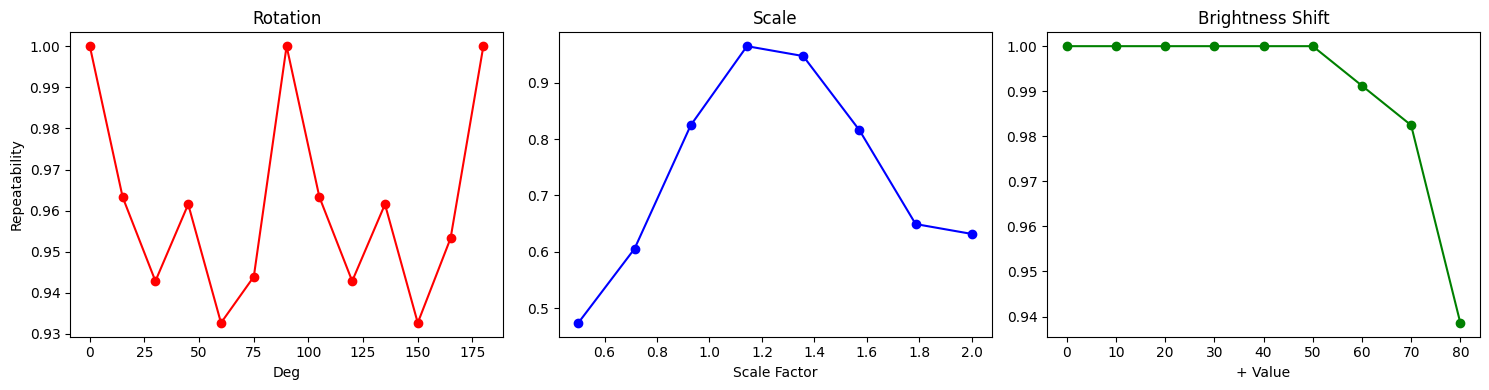


[TASK 5] Parameter Study & Comparison
Sigma   k       Gaussian       Box
1.0     0.02    241            248
1.0     0.04    188            204
1.0     0.06    164            156
1.5     0.02    161            256
1.5     0.04    138            239
1.5     0.06    128            177
2.0     0.02    124            244
2.0     0.04    112            232
2.0     0.06    98             172

Runtime: Custom = 7.52 ms | OpenCV = 1.22 ms
Custom Corners: 48 | OpenCV Corners: 547


In [7]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import time
import os

# ==========================================================================
# TASK 1: FILTERING FOUNDATIONS
# ==========================================================================

def convolve2d(image, kernel, padding='reflect'):
    image = np.asarray(image, dtype=np.float32)
    kernel = np.asarray(kernel, dtype=np.float32)
    kernel = np.flip(kernel)

    kh, kw = kernel.shape
    assert kh % 2 == 1 and kw % 2 == 1, "Kernel size must be odd."

    ph, pw = kh // 2, kw // 2
    h, w = image.shape

    if padding == 'reflect':
        padded = np.pad(image, ((ph, ph), (pw, pw)), mode='reflect')
    elif padding == 'zero':
        padded = np.pad(image, ((ph, ph), (pw, pw)), mode='constant', constant_values=0)
    else:
        raise ValueError("Padding must be 'zero' or 'reflect'")

    output = np.zeros_like(image)
    for r in range(kh):
        for c in range(kw):
            output += padded[r : r + h, c : c + w] * kernel[r, c]

    return output

def convolve1d(image, kernel1d, axis=0, padding='reflect'):
    image = np.asarray(image, dtype=np.float32)
    kernel1d = np.asarray(kernel1d, dtype=np.float32).flatten()
    kernel1d = np.flip(kernel1d)

    k_len = len(kernel1d)
    p = k_len // 2
    h, w = image.shape

    if axis == 0:
        padded = np.pad(image, ((p, p), (0, 0)), mode=padding)
        output = np.zeros_like(image)
        for r in range(k_len):
            output += padded[r : r + h, :] * kernel1d[r]
    else:
        padded = np.pad(image, ((0, 0), (p, p)), mode=padding)
        output = np.zeros_like(image)
        for c in range(k_len):
            output += padded[:, c : c + w] * kernel1d[c]

    return output

def separable_gaussian_filter(image, kernel_x, kernel_y, padding='reflect'):
    temp = convolve1d(image, kernel_x, axis=1, padding=padding)
    return convolve1d(temp, kernel_y, axis=0, padding=padding)

def get_gaussian_kernel(sigma):
    radius = int(np.ceil(3 * sigma))
    size = 2 * radius + 1
    x = np.arange(-radius, radius + 1, dtype=np.float32)
    kernel = np.exp(-0.5 * (x / sigma) ** 2)
    kernel /= kernel.sum()
    return kernel

sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32) / 8.0
sobel_y = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float32) / 8.0

# ==========================================================================
# LOADING IMAGES (COLAB SAFE)
# ==========================================================================

def load_image_safely(filename):
    # Try standard Colab upload path, then root, then current dir
    paths = [f"/content/{filename}", f"./{filename}", f"/content/drive/MyDrive/{filename}"]
    for p in paths:
        if os.path.exists(p):
            img = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
            if img is not None:
                return cv2.resize(img, (256, 256)).astype(np.float32)
    raise FileNotFoundError(f"Could not find {filename}. Please upload it to Colab.")

print("Loading images...")
img_checkerboard = load_image_safely('CHECKERBOARD.png')
img_structured   = load_image_safely('LIBRARY.png')
img_textured     = load_image_safely('NATURAL.png')
img_low_contrast = load_image_safely('FOGGY.png')

# ==========================================================================
# TASK 1 VERIFICATION
# ==========================================================================
print("\n[TASK 1] Verifying 2D Separability & Speedups")
for sig in [1.0, 2.0, 4.0]:
    g_1d = get_gaussian_kernel(sig)
    g_2d = np.outer(g_1d, g_1d)

    t0 = time.time()
    res_2d = convolve2d(img_checkerboard, g_2d)
    t2d = time.time() - t0

    t0 = time.time()
    res_1d = separable_gaussian_filter(img_checkerboard, g_1d, g_1d)
    t1d = time.time() - t0

    print(f"  Sigma={sig:.1f}: Speedup = {t2d/t1d:.2f}x, Max Diff = {np.max(np.abs(res_2d - res_1d)):.2e}")

# ==========================================================================
# TASK 2 & 3: HARRIS DETECTOR IMPLEMENTATION
# ==========================================================================

def harris_corner_detector(image, k=0.04, sigma=1.0, threshold_ratio=0.01, window_type='gaussian', return_tensor=False):
    Ix = convolve2d(image, sobel_x, padding='reflect')
    Iy = convolve2d(image, sobel_y, padding='reflect')

    Ix2, Iy2, Ixy = Ix * Ix, Iy * Iy, Ix * Iy

    if window_type == 'gaussian':
        g_kernel = get_gaussian_kernel(sigma)
        Sxx = separable_gaussian_filter(Ix2, g_kernel, g_kernel)
        Syy = separable_gaussian_filter(Iy2, g_kernel, g_kernel)
        Sxy = separable_gaussian_filter(Ixy, g_kernel, g_kernel)
    else:
        box_size = int(np.ceil(3 * sigma)) * 2 + 1
        box_kernel = np.ones((box_size, box_size), dtype=np.float32) / (box_size ** 2)
        Sxx = convolve2d(Ix2, box_kernel)
        Syy = convolve2d(Iy2, box_kernel)
        Sxy = convolve2d(Ixy, box_kernel)

    det_M = Sxx * Syy - Sxy**2
    trace_M = Sxx + Syy
    R = det_M - k * (trace_M**2)

    # NMS 3x3 Vectorized
    h, w = R.shape
    padded_R = np.pad(R, 1, mode='constant', constant_values=-np.inf)
    is_max = np.ones_like(R, dtype=bool)
    for dr in [-1, 0, 1]:
        for dc in [-1, 0, 1]:
            if dr == 0 and dc == 0: continue
            is_max &= (R >= padded_R[1+dr : 1+dr+h, 1+dc : 1+dc+w])

    max_r = np.max(R)
    threshold = threshold_ratio * max_r if max_r > 0 else 0
    corners = is_max & (R > threshold)
    corner_pts = np.argwhere(corners)

    if return_tensor:
        return corner_pts, R, Sxx, Syy, Sxy
    return corner_pts, R

print("\n[TASK 2] Detecting corners...")
pts_checker, R_checker, Sxx_c, Syy_c, Sxy_c = harris_corner_detector(img_checkerboard, k=0.04, sigma=1.5, return_tensor=True)
pts_struct, R_struct = harris_corner_detector(img_structured, k=0.04, sigma=1.5)
pts_text, R_text = harris_corner_detector(img_textured, k=0.04, sigma=1.5, threshold_ratio=0.02)
pts_low, R_low = harris_corner_detector(img_low_contrast, k=0.04, sigma=1.5, threshold_ratio=0.01)

fig, axs = plt.subplots(2, 4, figsize=(18, 9))
# Row 1: Overlays
axs[0, 0].imshow(img_checkerboard, cmap='gray'); axs[0, 0].scatter(pts_checker[:, 1], pts_checker[:, 0], color='red', s=15); axs[0, 0].set_title(f"Checkerboard ({len(pts_checker)})")
axs[0, 1].imshow(img_structured, cmap='gray'); axs[0, 1].scatter(pts_struct[:, 1], pts_struct[:, 0], color='red', s=15); axs[0, 1].set_title(f"Library ({len(pts_struct)})")
axs[0, 2].imshow(img_textured, cmap='gray'); axs[0, 2].scatter(pts_text[:, 1], pts_text[:, 0], color='red', s=15); axs[0, 2].set_title(f"Natural ({len(pts_text)})")
axs[0, 3].imshow(img_low_contrast, cmap='gray'); axs[0, 3].scatter(pts_low[:, 1], pts_low[:, 0], color='red', s=15); axs[0, 3].set_title(f"Foggy ({len(pts_low)})")
# Row 2: Heatmaps
for i, (R, title) in enumerate(zip([R_checker, R_struct, R_text, R_low], ["Checker", "Library", "Natural", "Foggy"])):
    im = axs[1, i].imshow(R, cmap='jet')
    fig.colorbar(im, ax=axs[1, i])
    axs[1, i].set_title(f"R Map: {title}")
plt.tight_layout(); plt.show()

# ==========================================================================
# TASK 3: EIGENVALUE ANALYSIS
# ==========================================================================
print("\n[TASK 3] Eigenvalue Analysis")
trace = Sxx_c + Syy_c
det = Sxx_c * Syy_c - Sxy_c**2
disc = np.clip((trace / 2.0)**2 - det, 0, None)
l1 = (trace / 2.0) + np.sqrt(disc)
l2 = (trace / 2.0) - np.sqrt(disc)

# Identity check
print(f"  Max error det(M) - L1*L2: {np.max(np.abs(det - l1*l2)):.2e}")
print(f"  Max error trace(M) - L1+L2: {np.max(np.abs(trace - (l1+l2))):.2e}")

# Classification thresholds (adjust for scale)
flat_mask = (l1 < 2.0) & (l2 < 2.0)
edge_mask = ((l1 >= 2.0) | (l2 >= 2.0)) & (np.abs(l1 - l2) > 15.0)
corner_mask = (l1 >= 2.0) & (l2 >= 2.0) & (np.abs(l1 - l2) <= 15.0)

plt.figure(figsize=(8, 6))
plt.scatter(l1[flat_mask], l2[flat_mask], color='gray', s=1, label='Flat')
plt.scatter(l1[edge_mask], l2[edge_mask], color='blue', s=1, label='Edge')
plt.scatter(l1[corner_mask], l2[corner_mask], color='red', s=5, label='Corner')

# Correct theoretical boundaries
x_vals = np.linspace(0, np.max(l1), 100)
r_min_k04 = ((1 - 2*0.04) - np.sqrt(1 - 4*0.04)) / (2*0.04)
r_min_k06 = ((1 - 2*0.06) - np.sqrt(1 - 4*0.06)) / (2*0.06)
plt.plot(x_vals, x_vals * r_min_k04, 'g--', label=f'k=0.04 bound (r={r_min_k04:.3f})')
plt.plot(x_vals, x_vals * r_min_k06, 'y--', label=f'k=0.06 bound (r={r_min_k06:.3f})')

plt.xlabel(r'\(\lambda_1\) (Max)'); plt.ylabel(r'\(\lambda_2\) (Min)')
plt.title(r'Eigenvalue Space Classification')
plt.legend(); plt.grid(True); plt.show()

# ==========================================================================
# TASK 4: INVARIANCE EXPERIMENTS
# ==========================================================================
print("\n[TASK 4] Invariance Sweeps (this might take 10-20 seconds)...")

def evaluate_repeatability(img_b, transform_matrix, corners_a, corners_b):
    if len(corners_a) == 0 or len(corners_b) == 0: return 0.0
    homog_a = np.hstack([corners_a[:, [1, 0]], np.ones((len(corners_a), 1))])
    mapped_a = (transform_matrix @ homog_a.T).T
    h, w = img_b.shape
    valid = (mapped_a[:, 0] >= 0) & (mapped_a[:, 0] < w) & (mapped_a[:, 1] >= 0) & (mapped_a[:, 1] < h)
    mapped_a = mapped_a[valid]
    if len(mapped_a) == 0: return 0.0

    b_xy = corners_b[:, [1, 0]]
    dists = np.linalg.norm(mapped_a[:, None, :2] - b_xy[None, :, :2], axis=2)
    return np.sum(np.min(dists, axis=1) <= 2) / len(mapped_a)

def get_corners(img, use_fixed=None):
    if use_fixed is not None:
        # Hack for fixed threshold: set ratio so that threshold = fixed value
        _, R = harris_corner_detector(img, sigma=1.5, threshold_ratio=0.0)
        pts, _ = harris_corner_detector(img, sigma=1.5, threshold_ratio=use_fixed/np.max(R))
        return pts
    pts, _ = harris_corner_detector(img, sigma=1.5, threshold_ratio=0.02)
    return pts

# Use a smaller region of the natural image for faster sweeps
base_img = img_structured # Use structured (Library) for clean testing
rots = list(range(0, 181, 15))
rep_rot = []
for deg in rots:
    M = cv2.getRotationMatrix2D((base_img.shape[1]/2, base_img.shape[0]/2), deg, 1.0)
    rot_img = cv2.warpAffine(base_img, M, (base_img.shape[1], base_img.shape[0]), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    cA, cB = get_corners(base_img), get_corners(rot_img)
    rep_rot.append(evaluate_repeatability(rot_img, M, cA, cB))

scales = np.linspace(0.5, 2.0, 8)
rep_scale = []
for s in scales:
    h, w = base_img.shape
    sc_img = cv2.resize(base_img, (int(w*s), int(h*s)))
    S = np.array([[s, 0, 0], [0, s, 0], [0, 0, 1]])
    cA, cB = get_corners(base_img), get_corners(sc_img)
    rep_scale.append(evaluate_repeatability(sc_img, S, cA, cB))

brights = list(range(0, 81, 10))
rep_bright = []
for b in brights:
    br_img = np.clip(base_img + b, 0, 255).astype(np.float32)
    cA, cB = get_corners(base_img), get_corners(br_img)
    rep_bright.append(evaluate_repeatability(br_img, np.eye(3), cA, cB))

plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1); plt.plot(rots, rep_rot, 'o-r'); plt.title('Rotation'); plt.xlabel('Deg'); plt.ylabel('Repeatability')
plt.subplot(1, 3, 2); plt.plot(scales, rep_scale, 'o-b'); plt.title('Scale'); plt.xlabel('Scale Factor')
plt.subplot(1, 3, 3); plt.plot(brights, rep_bright, 'o-g'); plt.title('Brightness Shift'); plt.xlabel('+ Value')
plt.tight_layout(); plt.show()

# ==========================================================================
# TASK 5: PARAMETER STUDY AND COMPARISON
# ==========================================================================
print("\n[TASK 5] Parameter Study & Comparison")

print(f"{'Sigma':<8}{'k':<8}{'Gaussian':<15}{'Box'}")
for s in [1.0, 1.5, 2.0]:
    for k_val in [0.02, 0.04, 0.06]:
        pts_g, _ = harris_corner_detector(img_structured, k=k_val, sigma=s, window_type='gaussian')
        pts_b, _ = harris_corner_detector(img_structured, k=k_val, sigma=s, window_type='box')
        print(f"{s:<8}{k_val:<8}{len(pts_g):<15}{len(pts_b)}")

# OpenCV Comparison
t0 = time.time()
c_custom, _ = harris_corner_detector(img_checkerboard, k=0.04, sigma=1.5)
t_custom = time.time() - t0

t0 = time.time()
R_cv = cv2.cornerHarris(np.uint8(img_checkerboard), 2, 3, 0.04)
thr_cv = 0.01 * R_cv.max()
c_cv = np.argwhere(R_cv > thr_cv) # Simplified comparison for Colab
t_cv = time.time() - t0

print(f"\nRuntime: Custom = {t_custom*1000:.2f} ms | OpenCV = {t_cv*1000:.2f} ms")
print(f"Custom Corners: {len(c_custom)} | OpenCV Corners: {len(c_cv)}")